# 11 — Connecting Predictions to Recommendations

**Milestone 4 · Task 12.** Create the rules and logic that connect campaign
characteristics and model predictions to specific recommendations, making
sure every recommendation is based on the project's findings.

**How the numbers here are produced.** The chance of success comes from the
final model (calibrated Random Forest). The *effect* of a change comes from
the Logistic Regression advisor, added in percentage points to the forest's
score (`Recommender.what_if_proba`; why, in notebook 10 §11.8). Every
"gain" in this notebook is measured that way.

The rules live in `src/recommend.py`. This notebook shows how each one works,
tests it across the whole held-out set, and records the decisions that came
out of that testing — including two levers that were considered and
rejected.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.prepare import load_splits
from src.recommend import (
    Recommender, RAW_COLUMNS, MIN_GAIN, BANDS, GOAL_FACTORS, DURATION_TARGETS,
    TIER_TARGETS, MIN_TIER_ADDITION, DEFAULT_DURATION, GOAL_FLOOR_QUANTILE, suggest_tiers,
    tiers_to_string, string_to_tiers, NICE_AMOUNTS,
)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
FIG = Path("../reports/figures")

train, test = load_splits("..")["random"]
rec = Recommender.fit(test=test, train=train)
raw_test = test[RAW_COLUMNS].copy()
print(f"{len(test):,} held-out campaigns available for stress-testing")

7,676 held-out campaigns available for stress-testing


## 12.1 The rules in one table

Every number the advice engine relies on is a named constant at the top of
`src/recommend.py`, so a rule can be challenged and changed in one place.

In [2]:
pd.DataFrame([
    ("MIN_GAIN", f"{MIN_GAIN:.0%}", "Smallest predicted gain worth recommending. Held-out calibration is within a few points in every decile, so smaller gains sit inside the noise."),
    ("GOAL_FACTORS", str(GOAL_FACTORS), "Candidate goals as a fraction of the current one, mildest first. Never below half."),
    ("GOAL_FLOOR_QUANTILE", f"{GOAL_FLOOR_QUANTILE:.0%}", "A suggested goal never falls below this quantile of the subcategory's goals."),
    ("DURATION_TARGETS", f"{DURATION_TARGETS} days", "Candidate durations, only offered to campaigns running past the default. Never 30."),
    ("DEFAULT_DURATION", str(DEFAULT_DURATION), "The platform default window. No advice is given from or to it (see 12.5)."),
    ("TIER_TARGETS", str(TIER_TARGETS), "Candidate total numbers of reward tiers."),
    ("MIN_TIER_ADDITION", str(MIN_TIER_ADDITION), "A tier candidate must add at least this many tiers. Testing showed \"add a tenth tier\" to someone with nine is noise, not advice."),
    ("BANDS", str([(f'<{u:.0%}', n) for u, n in BANDS]), "Risk bands by predicted probability."),
], columns=["constant", "value", "what it does"])

,constant,value,what it does
0,MIN_GAIN,2%,Smallest predicted gain worth recommending. Held-out calibration is within a few point...
1,GOAL_FACTORS,"[0.9, 0.75, 0.6, 0.5]","Candidate goals as a fraction of the current one, mildest first. Never below half."
2,GOAL_FLOOR_QUANTILE,10%,A suggested goal never falls below this quantile of the subcategory's goals.
3,DURATION_TARGETS,"[45, 35, 28] days","Candidate durations, only offered to campaigns running past the default. Never 30."
4,DEFAULT_DURATION,"(29.5, 30.5)",The platform default window. No advice is given from or to it (see 12.5).
5,TIER_TARGETS,"[6, 8, 10]",Candidate total numbers of reward tiers.
6,MIN_TIER_ADDITION,2,"A tier candidate must add at least this many tiers. Testing showed ""add a tenth tier"" ..."
7,BANDS,"[('<35%', 'High risk'), ('<55%', 'Moderate risk'), ('<101%', 'Favourable')]",Risk bands by predicted probability.


The selection rule: for each lever, recommend the **mildest candidate that
clears `MIN_GAIN`**. Showing every candidate alongside lets the creator see
the whole trade-off, but the headline advice is the smallest change that
moves the needle — the one most likely to actually be made.

## 12.2 Features are rebuilt from raw inputs, never patched

Changing the goal does not change one number. It changes every feature that
is derived from it. Patching a single column would leave the others
describing the old goal.

In [3]:
camp = dict(goal=40000, duration=45, reward_tiers=[10, 25, 50],
            category="Film & Video", subcategory="Documentary", state="CA")
c_before = rec.validate(camp)
c_after = rec.validate({**camp, "goal": 20000})
X1 = rec.featurize(rec.to_raw([c_before])).iloc[0]
X2 = rec.featurize(rec.to_raw([c_after])).iloc[0]
changed = pd.DataFrame({"goal $40,000": X1, "goal $20,000": X2})
changed = changed[changed.iloc[:, 0] != changed.iloc[:, 1]]
print(f"Halving the goal changed {len(changed)} of {len(X1)} model features:\n")
changed.round(3)

Halving the goal changed 5 of 137 model features:



,"goal $40,000","goal $20,000"
log_goal,10.597,9.904
log_goal_per_day,6.791,6.099
min_tier_pct_of_goal,0.000,0.000
log_goal_per_tier,9.498,8.805
log_goal_vs_subcat_median,1.792,1.253


Each of those is a goal-derived feature (goal per day, goal per tier, goal
relative to the subcategory median, entry price as a share of the goal).
Re-running the whole feature pipeline for every what-if keeps them
consistent. A test proves the rebuild matches the training matrix exactly:

In [4]:
check = rec.self_check()
check

{'rows_checked': 2000,
 'max_abs_difference': 0.0,
 'matrix_reproduced': True,
 'tier_round_trip_ok': True}

`max_abs_difference` of zero means that re-featurising 2,000 training
campaigns from their raw inputs reproduces the model's training matrix
exactly, so the what-if engine is asking the model the same question it was
trained on.

## 12.3 How each lever behaves across the held-out set

Each candidate change is applied to every eligible held-out campaign and the
change in predicted probability recorded. This is the test of whether a rule
is *systematically* sensible rather than sensible for one example.

In [5]:
def effect(lever, value, rows):
    """Change in predicted chance, in points, from applying one lever to `rows`."""
    before = rec.predict_proba(rows)
    after = rec.what_if_proba(rows, rec.apply_lever(rows, lever, value), base=before)
    return (after - before) * 100

records = []
def record(lever, label, gains):
    records.append({"lever": lever, "change": label, "campaigns": len(gains),
                    "mean gain (pts)": gains.mean(), "median gain (pts)": np.median(gains),
                    "share raised": float(np.mean(gains > 0)),
                    "share clearing MIN_GAIN": float(np.mean(gains >= MIN_GAIN * 100))})

for f in GOAL_FACTORS:
    record("goal", f"goal x {f}", effect("goal", f, raw_test))

dur = raw_test["duration"]
for target in sorted(DURATION_TARGETS, reverse=True):
    rows = raw_test[(dur > DEFAULT_DURATION[1]) & (dur <= 60) & (dur > target + 0.5)]
    record("duration", f"shorten to {target} days", effect("duration", target, rows))

for target in TIER_TARGETS:
    rows = raw_test[raw_test["levels"] <= target - MIN_TIER_ADDITION]
    rows = rows.sample(min(2500, len(rows)), random_state=0)
    record("reward tiers", f"{target} tiers", effect("reward tiers", target, rows))

lever_table = pd.DataFrame(records)
lever_table.round(3)

,lever,change,campaigns,mean gain (pts),median gain (pts),share raised,share clearing MIN_GAIN
0,goal,goal x 0.9,7676,1.248,1.230,0.999,0.076
1,goal,goal x 0.75,7676,3.537,3.616,0.999,0.870
2,goal,goal x 0.6,7676,6.188,6.323,0.999,0.960
3,goal,goal x 0.5,7676,8.267,8.480,0.999,0.979
4,duration,shorten to 45 days,1247,3.615,3.771,1.000,0.700
5,duration,shorten to 35 days,2505,4.272,3.449,1.000,0.708
6,duration,shorten to 28 days,3287,4.791,3.979,1.000,0.717
7,reward tiers,6 tiers,1211,16.532,11.931,0.998,0.993
8,reward tiers,8 tiers,2500,14.997,12.214,1.000,0.996
9,reward tiers,10 tiers,2500,15.309,11.941,1.000,0.994


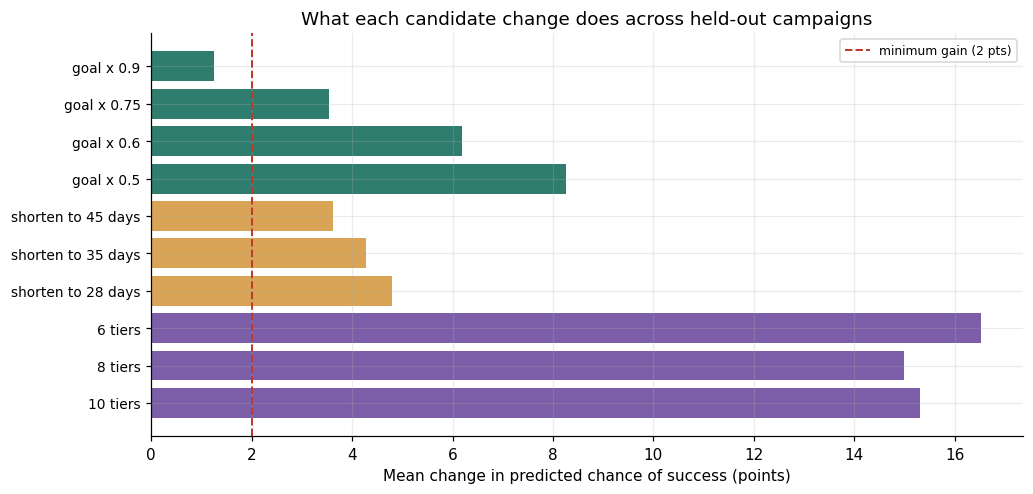

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
colors = {"goal": TEAL, "duration": SAND, "reward tiers": PLUM}
ax.barh(range(len(lever_table)), lever_table["mean gain (pts)"],
        color=[colors[l] for l in lever_table["lever"]])
ax.axvline(MIN_GAIN * 100, color=CORAL, ls="--", lw=1.3, label=f"minimum gain ({MIN_GAIN * 100:.0f} pts)")
ax.set_yticks(range(len(lever_table)))
ax.set_yticklabels(lever_table["change"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Mean change in predicted chance of success (points)")
ax.set_title("What each candidate change does across held-out campaigns")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_lever_response.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading it.**

- **Reward tiers is by far the strongest lever** — about 15 points on
  average where at least two tiers are added (median about 12) — which
  matches the strongest pattern in the EDA.
- **Goal and duration are comparable at mild settings**: a 25% goal cut
  gains about 3.5 points, and shortening a long campaign gains roughly 3.6
  to 4.8.
- **Consistency:** every lever raises the predicted chance for essentially
  every eligible campaign (share raised of 99.8% or more). A lever that helps
  on average while hurting a large minority would be a poor rule; none does.
- **Why the mildest goal cut is usually 25%:** trimming the goal by only 10%
  clears the 2-point bar for under one campaign in ten.

## 12.4 The "mildest change" rule on one campaign

All candidates are shown, the mildest that clears the minimum gain is
marked, and that is the one that goes into the combined plan.

In [7]:
a = rec.assess(camp)
a.options.assign(probability=lambda d: d.probability.map("{:.1%}".format),
                 gain_pp=lambda d: d.gain_pp.round(1),
                 funding_floor=lambda d: d.funding_floor.map("${:,.0f}".format))[
    ["lever", "change", "probability", "gain_pp", "recommended"]]

,lever,change,probability,gain_pp,recommended
0,goal,"Lower the goal to $36,000",7.7%,0.8,False
1,goal,"Lower the goal to $30,000",9.2%,2.4,True
2,goal,"Lower the goal to $24,000",11.3%,4.4,False
3,goal,"Lower the goal to $20,000",13.2%,6.3,False
4,duration,Shorten the campaign to 35 days,8.3%,1.4,False
5,duration,Shorten the campaign to 28 days,9.2%,2.3,True
6,reward tiers,"Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)",16.5%,9.6,True
7,reward tiers,"Offer 8 reward tiers ($10,$15,$20,$25,$30,$40,$50,$100)",23.6%,16.7,False
8,reward tiers,"Offer 10 reward tiers ($10,$15,$20,$25,$30,$40,$50,$60,$75,$100)",29.9%,23.1,False


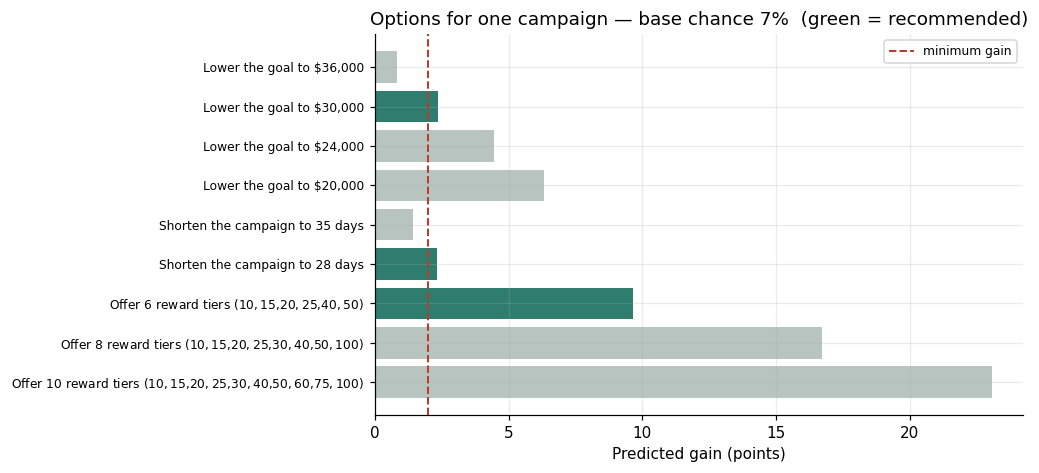


Combined plan: 6.9% -> 25.1%
  - Lower the goal to $30,000
  - Shorten the campaign to 28 days
  - Offer 6 reward tiers ($10,$15,$20,$25,$40,$50)


In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
o = a.options
ax.barh(range(len(o)), o["gain_pp"],
        color=[TEAL if r else "#B8C4C0" for r in o["recommended"]])
ax.axvline(MIN_GAIN * 100, color=CORAL, ls="--", lw=1.3, label="minimum gain")
ax.set_yticks(range(len(o))); ax.set_yticklabels(o["change"], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("Predicted gain (points)")
ax.set_title(f"Options for one campaign — base chance {a.probability:.0%}  (green = recommended)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m4_example_options.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"\nCombined plan: {a.probability:.1%} -> {a.plan['probability']:.1%}")
for ch in a.plan["changes"]:
    print("  -", ch)

## 12.5 Why exactly 30 days is never a source or target of advice

September's notebook said the 30-day default *outperforms*. It does not. The
question here is what to do about the dip, since advice like "run 28 days
instead of 30" would be a gimmick if the dip is not caused by the length.

In [9]:
t = train.copy()
t["dur_b"] = pd.cut(t["duration_days"], [0, 25, 29.5, 30.5, 35, 45, 60, 100],
                    labels=["<=25", "26-29", "30 (default)", "31-35", "36-45", "46-60", ">60"])
dur_tbl = t.groupby("dur_b", observed=True)["success"].agg(["mean", "size"])
dur_tbl.columns = ["success_rate", "campaigns"]
print(dur_tbl.round(3).to_string())

              success_rate  campaigns
dur_b                                
<=25                 0.685       3631
26-29                0.702       1112
30 (default)         0.530       9288
31-35                0.636       3045
36-45                0.554       4882
46-60                0.473       5327
>60                  0.426       3417


In [10]:
# What does the MODEL do with a one-day change across the default?
_b = rec.predict_proba(raw_test)
def _at(days):
    return rec.what_if_proba(raw_test, rec.apply_lever(raw_test, "duration", days), base=_b)
p30, p29, p31, p35, p28 = _at(30), _at(29), _at(31), _at(35), _at(28)
print(f"29 days vs 30 days: {(p29 - p30).mean() * 100:+.1f} points on average")
print(f"31 days vs 30 days: {(p31 - p30).mean() * 100:+.1f} points on average")
print(f"28 days vs 30 days: {(p28 - p30).mean() * 100:+.1f} points on average")
print(f"35 days vs 30 days: {(p35 - p30).mean() * 100:+.1f} points on average")

29 days vs 30 days: +5.9 points on average
31 days vs 30 days: +5.5 points on average
28 days vs 30 days: +6.1 points on average
35 days vs 30 days: +4.5 points on average


**What this shows.** Campaigns left at exactly 30 days succeeded at a clearly
lower rate than the 26-29 and 31-35 day groups on either side — and the
model reproduces that: moving *one day* either way changes its prediction by
about **5.5 to 5.9 points**.

One day of campaign length cannot plausibly do that. The model is reacting
to the "is exactly 30 days" flag, which marks campaigns whose creators left
the platform default untouched. That is a statement about who accepts
defaults — likely creators who planned less — not about what 30 days does.
Advice such as "run 28 days instead of 30" would promise a gain the creator
cannot buy by changing a number.

**Decision:** the engine never recommends a duration from or to the 30-day
window, and says so in the report. The shortening advice it does give applies
only to campaigns running *past* the default, where the pattern is a smooth
decline rather than a one-day cliff.

## 12.6 Entry price: considered and rejected

Two questions. Does the model respond to a cheaper entry tier? And is the
response about the *price* of the added tier or just the extra tier?

In [11]:
tiers = raw_test["reward_levels"].map(string_to_tiers)
base_all = rec.predict_proba(raw_test)

def with_added(tier_fn, mask):
    new = [tiers_to_string(sorted(set(x + [tier_fn(x)]))) if m else s
           for x, s, m in zip(tiers, raw_test["reward_levels"], mask)]
    r = raw_test.copy()
    r["reward_levels"] = new
    r["levels"] = [len(string_to_tiers(v)) for v in new]
    return (rec.what_if_proba(raw_test, r, base=base_all) - base_all) * 100

entry = tiers.map(min)
rows = []
for label, mask in [("entry $11-25", entry.between(10.01, 25).to_numpy()),
                    ("entry above $25", entry.gt(25).to_numpy())]:
    g = with_added(lambda x: 10.0, mask)
    rows.append({"campaigns": label, "n": int(mask.sum()),
                 "add a $10 tier: mean gain (pts)": g[mask].mean(),
                 "share raised": float(np.mean(g[mask] > 0))})
pd.DataFrame(rows).round(2)

,campaigns,n,add a $10 tier: mean gain (pts),share raised
0,entry $11-25,837,2.12,0.89
1,entry above $25,139,0.14,0.46


In [12]:
# Same campaigns, same number of added tiers -- cheap tier vs expensive tier.
mask = tiers.map(len).between(2, 8).to_numpy()
cheap = with_added(lambda x: 10.0 if 10.0 not in x else 15.0, mask)
top = with_added(lambda x: float(min((a for a in NICE_AMOUNTS if a >= 2 * max(x)), default=2 * max(x))), mask)
print(f"Campaigns with 2-8 tiers: {mask.sum():,}")
print(f"Add a CHEAP tier ($10):            {cheap[mask].mean():+.2f} points on average")
print(f"Add an EXPENSIVE tier (2x the top): {top[mask].mean():+.2f} points on average")

Campaigns with 2-8 tiers: 4,597
Add a CHEAP tier ($10):            +3.44 points on average
Add an EXPENSIVE tier (2x the top): +3.71 points on average


**What this shows.**

- Adding a $10 tier to campaigns whose cheapest reward is above $25 moves
  the prediction by only about **0.1 points** — almost nothing. The cheaper
  entry price does not help.
- Adding an expensive top-end tier does **at least as well** as adding a
  cheap one (about +3.7 versus +3.4 points).

So the model responds to the *number* of tiers, not to how cheap the
cheapest one is. That agrees with notebook 10, where the entry-price gap
shrank to a few points once goal size and tier count were held fixed.

**Decision:** there is no entry-price lever. The tier lever speaks only of
the number of tiers, and the report explains why a high entry price is not
the thing to fix.

## 12.7 Suggested tiers look like tiers a creator would offer

New tiers fill the widest price gaps (measured in log-price) and snap to
believable amounts. If there is no room left between the extremes, a
higher-priced tier is added instead of cramming in $12, $13, $15.

In [13]:
examples = [[5, 25, 100], [10, 25], [25], [5, 500], [1, 2], [5, 25, 50]]
pd.DataFrame([{"current tiers": tiers_to_string(e), "target": n,
               "suggested": tiers_to_string(suggest_tiers(e, n)),
               "result count": len(suggest_tiers(e, n))}
              for e, n in [(e, 8) for e in examples]])

,current tiers,target,suggested,result count
0,"$5,$25,$100",8,"$5,$10,$15,$25,$40,$50,$75,$100",8
1,"$10,$25",8,"$10,$15,$20,$25,$30,$40,$50,$100",8
2,$25,8,"$25,$40,$50,$75,$100,$150,$250,$500",8
3,"$5,$500",8,"$5,$10,$15,$25,$50,$150,$250,$500",8
4,"$1,$2",8,"$1,$2,$3,$5,$10,$15,$20,$40",8
5,"$5,$25,$50",8,"$5,$10,$15,$20,$25,$30,$40,$50",8


## 12.8 Why the plan is re-predicted, not added up

Goal, duration and tiers interact: the goal-per-day and goal-per-tier
features each involve two levers at once. So the combined effect is not the
sum of the individual effects, and the plan is always a fresh prediction.

In [14]:
at_risk = test[rec.holdout_p < BANDS[1][0]]
at_risk = at_risk[at_risk["duration_days"] <= 60].sample(200, random_state=1)
from src.recommend import campaign_from_row

gaps = []
for _, row in at_risk.iterrows():
    res = rec.assess(campaign_from_row(row))
    if res.plan is not None and res.options["recommended"].sum() > 1:
        individual = res.options.loc[res.options["recommended"], "gain_pp"].sum()
        gaps.append({"sum of individual gains": individual,
                     "actual combined gain": res.plan["gain_pp"]})
gaps = pd.DataFrame(gaps)
gaps["combined minus sum"] = gaps["actual combined gain"] - gaps["sum of individual gains"]
print(f"{len(gaps)} campaigns with two or more recommendations")
gaps.describe().loc[["mean", "50%", "min", "max"]].round(2)

173 campaigns with two or more recommendations


,sum of individual gains,actual combined gain,combined minus sum
mean,16.50,17.03,0.53
50%,14.76,15.62,0.34
min,4.38,4.87,-3.15
max,54.55,54.88,8.33


**What this shows.** On average the combined gain is close to the sum of the
individual gains (about 17.0 versus 16.2 points), so the interaction is
usually small. But for individual campaigns they differ by as much as 8.6
points in one direction and 4.2 in the other — the goal-per-day and
goal-per-tier features each involve two levers at once, and probabilities
are not additive near the extremes.

That is enough to justify the rule: **the plan is always a fresh
prediction**, never a sum shown to the creator.

## 12.9 Save

In [15]:
lever_table.round(4).to_csv("../reports/m4_lever_effects.csv", index=False)
dur_tbl.round(4).to_csv("../reports/m4_duration_buckets.csv")
print("Wrote m4_lever_effects.csv, m4_duration_buckets.csv")

Wrote m4_lever_effects.csv, m4_duration_buckets.csv


## Task 12 — Summary

## Decisions made in this notebook

| Decision | Basis |
|---|---|
| Three levers only: goal, duration (past the default only), number of reward tiers | The only controllable factors with real signal (notebook 10) |
| Recommend the **mildest** candidate clearing 2 points | Small changes get made; a 10% goal cut rarely clears the bar, so the usual cut is 25% |
| Never advise from or to exactly 30 days | A one-day move across the default shifts the prediction by ~5.5 points, which is the default flag, not the duration |
| **No entry-price lever** | The gap is a tier-count effect; adding a $10 tier to a >$25 entry moves the prediction ~0.1 point |
| Tier lever is about *count* | An expensive added tier does as well as a cheap one |
| Features rebuilt from raw inputs | Halving the goal changes 5 model features at once; the rebuild reproduces the training matrix exactly |
| Combined plan is re-estimated as one change | Usually close to the sum, but differs by up to ~9 points for some campaigns |

## Honest limits of the rules

- **Reward tiers is the strongest lever and the most exposed to selection.**
  Creators who build many tiers probably planned the campaign more
  carefully. The report says so beside any tier advice.
- **Predicted gains are associations.** They describe how campaigns with those
  characteristics fared, not what changing one characteristic would cause.

**Next:** `12_prototype.ipynb` packages these rules into a reusable function
that takes a campaign description and returns a prediction and advice.